In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

True

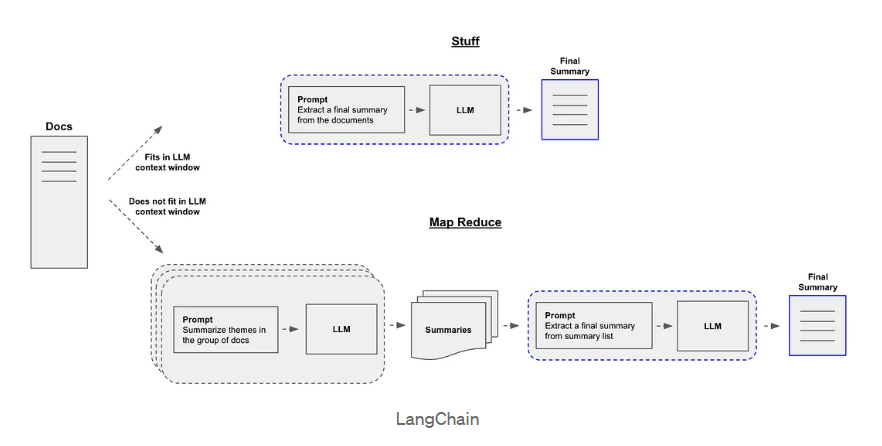

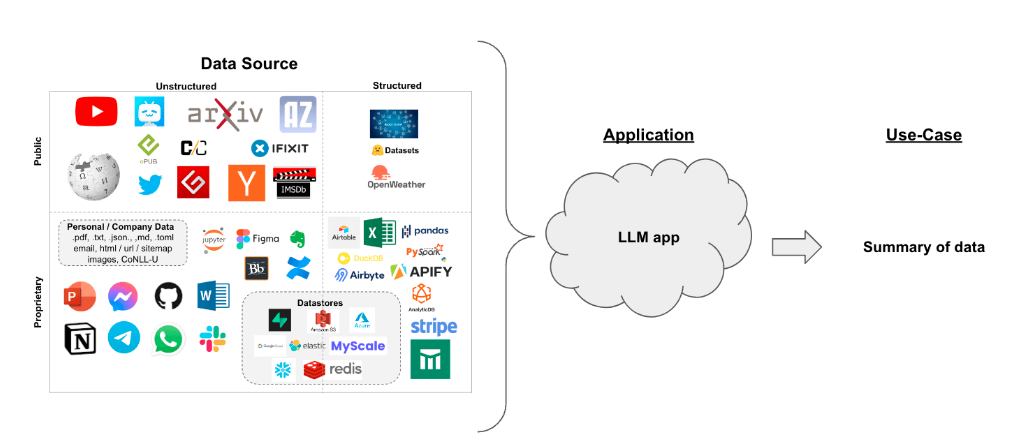

https://medium.com/@AI-Simplified/summarize-large-documents-or-text-using-llms-and-langchain-3116543df4ba

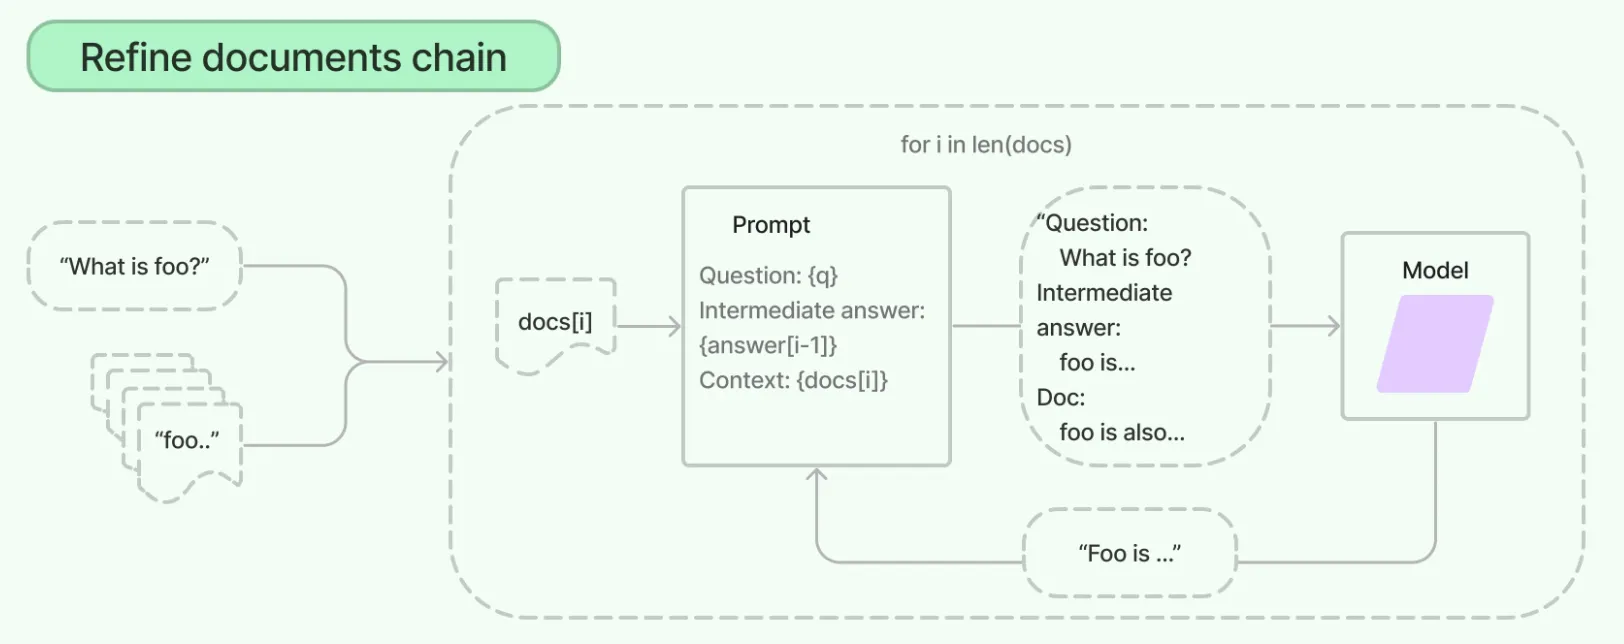

In [19]:
from langchain_groq import ChatGroq
api_key=os.getenv("GROQ_API_KEY")
llm=ChatGroq(groq_api_key=api_key,model="llama-3.1-8b-instant")
llm

ChatGroq(profile={'max_input_tokens': 131072, 'max_output_tokens': 8192, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True}, client=<groq.resources.chat.completions.Completions object at 0x000002468A53AFC0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002468A538590>, model_name='llama-3.1-8b-instant', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [20]:
from langchain_classic.schema import(
    AIMessage,
    HumanMessage,SystemMessage
)


In [6]:
speech="""
People across the country, involved in government, political, and social activities, are dedicating their time to make the ‘Viksit Bharat Sankalp Yatra’ (Developed India Resolution Journey) successful. Therefore, as a Member of Parliament, it was my responsibility to also contribute my time to this program. So, today, I have come here just as a Member of Parliament and your ‘sevak’, ready to participate in this program, much like you.

In our country, governments have come and gone, numerous schemes have been formulated, discussions have taken place, and big promises have been made. However, my experience and observations led me to believe that the most critical aspect that requires attention is ensuring that the government’s plans reach the intended beneficiaries without any hassles. If there is a ‘Pradhan Mantri Awas Yojana’ (Prime Minister’s housing scheme), then those who are living in jhuggis and slums should get their houses. And he should not need to make rounds of the government offices for this purpose. The government should reach him. Since you have assigned this responsibility to me, about four crore families have got their ‘pucca’ houses. However, I have encountered cases where someone is left out of the government benefits. Therefore, I have decided to tour the country again, to listen to people’s experiences with government schemes, to understand whether they received the intended benefits, and to ensure that the programs are reaching everyone as planned without paying any bribes. We will get the real picture if we visit them again. Therefore, this ‘Viksit Bharat Sankalp Yatra’ is, in a way, my own examination. I want to hear from you and the people across the country whether what I envisioned and the work I have been doing aligns with reality and whether it has reached those for whom it was meant.

It is crucial to check whether the work that was supposed to happen has indeed taken place. I recently met some individuals who utilized the Ayushman card to get treatment for serious illnesses. One person met with a severe accident, and after using the card, he could afford the necessary operation, and now he is recovering well. When I asked him, he said: “How could I afford this treatment? Now that there is the Ayushman card, I mustered courage and underwent an operation. Now I am perfectly fine.”  Such stories are blessings to me.

The bureaucrats, who prepare good schemes, expedite the paperwork and even allocate funds, also feel satisfied that 50 or 100 people who were supposed to get the funds have got it. The funds meant for a thousand villages have been released. But their job satisfaction peaks when they hear that their work has directly impacted someone’s life positively. When they see the tangible results of their efforts, their enthusiasm multiplies. They feel satisfied. Therefore, ‘Viksit Bharat Sankalp Yatra’ has had a positive impact on government officers. It has made them more enthusiastic about their work, especially when they witness the tangible benefits reaching the people. Officers now feel satisfied with their work, saying, “I made a good plan, I created a file, and the intended beneficiaries received the benefits.” When they find that the money has reached a poor widow under the Jeevan Jyoti scheme and it was a great help to her during her crisis, they realise that they have done a good job. When a government officer listens to such stories, he feels very satisfied.

There are very few who understand the power and impact of the ‘Viksit Bharat Sankalp Yatra’. When I hear people connected to bureaucratic circles talking about it, expressing their satisfaction, it resonates with me. I’ve heard stories where someone suddenly received 2 lakh rupees after the death of her husband, and a sister mentioned how the arrival of gas in her home transformed her lives. The most significant aspect is when someone says that the line between rich and poor has vanished. While the slogan ‘Garibi Hatao’ (Remove Poverty) is one thing, but the real change happens when a person says, “As soon as the gas stove came to my house, the distinction between poverty and affluence disappeared.
"""

In [7]:
speech

'\nPeople across the country, involved in government, political, and social activities, are dedicating their time to make the ‘Viksit Bharat Sankalp Yatra’ (Developed India Resolution Journey) successful. Therefore, as a Member of Parliament, it was my responsibility to also contribute my time to this program. So, today, I have come here just as a Member of Parliament and your ‘sevak’, ready to participate in this program, much like you.\n\nIn our country, governments have come and gone, numerous schemes have been formulated, discussions have taken place, and big promises have been made. However, my experience and observations led me to believe that the most critical aspect that requires attention is ensuring that the government’s plans reach the intended beneficiaries without any hassles. If there is a ‘Pradhan Mantri Awas Yojana’ (Prime Minister’s housing scheme), then those who are living in jhuggis and slums should get their houses. And he should not need to make rounds of the gove

In [8]:
chat_message=[
    SystemMessage(content="You are expert with experise in summarizing speeched"),
    HumanMessage(content=f"Please provide a short and concisse summary of the follow speech:\n Text:{speech}")
]

In [21]:
llm.get_num_tokens(speech)

909

## Prompt Template Text Summarization

In [23]:
from langchain_classic.chains import LLMChain
from langchain_classic import PromptTemplate

generictemplate="""
Write a summary of the following speech:
Speech:{speech}
Translate the precise summary to {language}
"""

prompt=PromptTemplate(
    input_variables=['speech','language'],
    template=generictemplate
)
prompt

PromptTemplate(input_variables=['language', 'speech'], input_types={}, partial_variables={}, template='\nWrite a summary of the following speech:\nSpeech:{speech}\nTranslate the precise summary to {language}\n')

In [24]:
complete_prompt=prompt.format(speech=speech,language="hindi")
complete_prompt

'\nWrite a summary of the following speech:\nSpeech:\nPeople across the country, involved in government, political, and social activities, are dedicating their time to make the ‘Viksit Bharat Sankalp Yatra’ (Developed India Resolution Journey) successful. Therefore, as a Member of Parliament, it was my responsibility to also contribute my time to this program. So, today, I have come here just as a Member of Parliament and your ‘sevak’, ready to participate in this program, much like you.\n\nIn our country, governments have come and gone, numerous schemes have been formulated, discussions have taken place, and big promises have been made. However, my experience and observations led me to believe that the most critical aspect that requires attention is ensuring that the government’s plans reach the intended beneficiaries without any hassles. If there is a ‘Pradhan Mantri Awas Yojana’ (Prime Minister’s housing scheme), then those who are living in jhuggis and slums should get their houses

In [25]:
llm.get_num_tokens(complete_prompt)

932

In [26]:
llm_chain=LLMChain(llm=llm,prompt=prompt)
summary=llm_chain.run({'speech':speech,'language':'hindi'})
summary

'Yeh aapke liye ek samajhdaar tareeka hai:\n\n"Viksit Bharat Sankalp Yatra" ke liye sabhi logon ne apni samay ko dene ke liye judne ki koshish ki hai. Isliye, maine bhi apne karyakal ki tarah apne dhan ki samay ko is yatra mein dene ke liye aaya hoon. Main aapke \'sevak\' ka roop mein aayaa hoon aur is yatra mein hamaare saath judna chaahunga.\n\nHumare desh mein sevaon ne aa gayi, nitiyon ne banai gayi, aur bahut se pradarshan huiye, lekin maine apne anubhav aur dekhbhaal ke anusaar yeh mana hai ki sabse mahatvapoorn cheez jo dhyan de sakti hai, usi hai ki sarkar ke planon se labh utpann hone wale logon tak pahunch paye bina koi mushkila ka saamna na karnaa. Agar Pradhan Mantri Awas Yojana hai, to logon ko unke ghar ke lie ghar mil jaye, aur unhein sarkari offis jana na padaaye. Sarkar unke paas pahunch jaye. Jab aapne mujhe yeh jimaar dene mein aapki madad ki hai, to charee crore parivaaron ne apna pucca ghar prapt kiya hai. Lekin maine dekha hai ki kabhi-kabhi kuchh logon ko sarkari

## StuffDocumentChain Text summarization

In [27]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader("apjspeech.pdf")
docs = loader.load_and_split()
docs

[Document(metadata={'producer': 'GPL Ghostscript 8.15', 'creator': 'PScript5.dll Version 5.2', 'creationdate': 'D:20070730160943', 'moddate': 'D:20070730160943', 'title': 'Microsoft Word - Document1', 'author': 'Shri', 'source': 'apjspeech.pdf', 'total_pages': 7, 'page': 0, 'page_label': '1'}, page_content='A P J Abdul Kalam Departing speech \n \n \nFriends, I am delighted to address you all, in the country and those livi ng abroad, after \nworking with you and completing five beautiful and eventful years in Rashtrapati \nBhavan. Today, it is indeed a thanks giving occasion. I would like to narr ate, how I \nenjoyed every minute of my tenure enriched by the wonderful assoc iation from each one \nof you, hailing from different walks of life, be it politics, sci ence and technology, \nacademics, arts, literature, business, judiciary, administration, local bodies, farming, \nhome makers, special children, media and above all from the youth and st udent \ncommunity who are the future wealt

In [28]:
template=""" Write a concise and short summary of the following speech,
Speech :{text}

 """
prompt=PromptTemplate(input_variables=['text'],
                      template=template)


In [30]:
from langchain_classic.chains.summarize import load_summarize_chain

In [31]:
chain=load_summarize_chain(llm,chain_type='stuff',prompt=prompt,verbose=True)
output_summary=chain.run(docs)
output_summary



> Entering new StuffDocumentsChain chain...


> Entering new LLMChain chain...
Prompt after formatting:
 Write a concise and short summary of the following speech,
Speech :A P J Abdul Kalam Departing speech 
 
 
Friends, I am delighted to address you all, in the country and those livi ng abroad, after 
working with you and completing five beautiful and eventful years in Rashtrapati 
Bhavan. Today, it is indeed a thanks giving occasion. I would like to narr ate, how I 
enjoyed every minute of my tenure enriched by the wonderful assoc iation from each one 
of you, hailing from different walks of life, be it politics, sci ence and technology, 
academics, arts, literature, business, judiciary, administration, local bodies, farming, 
home makers, special children, media and above all from the youth and st udent 
community who are the future wealth of our country. During my intera ction at 
Rashtrapati Bhavan in Delhi and at every state and union territor y as well as through my 
online in

'Here\'s a concise and short summary of the departing speech of A.P.J. Abdul Kalam:\n\nDr. A.P.J. Abdul Kalam, the President of India, addressed the nation in his departing speech, reflecting on his five-year tenure and the key messages he had shared with the public. He emphasized the importance of:\n\n1. Accelerating development and empowering the youth to achieve their dreams.\n2. Empowering villages to deal with their development and connect with urban societies.\n3. Mobilizing rural core competence for competitiveness and establishing PURA (Providing Urban Amenities in Rural Areas) complexes.\n4. Developing agriculture through the "Seed to Food" concept, empowering farmers, and increasing agricultural GDP growth.\n5. Defeating problems and succeeding through perseverance and partnership.\n6. Overcoming the impact of disasters through partnership and community efforts.\n7. Combating calamities with courage and resilience.\n8. Achieving connectivity for societal transformation throug

### Map reduce to Summarize Large documents

In [32]:
from langchain_classic.text_splitter import RecursiveCharacterTextSplitter

In [33]:
docs

[Document(metadata={'producer': 'GPL Ghostscript 8.15', 'creator': 'PScript5.dll Version 5.2', 'creationdate': 'D:20070730160943', 'moddate': 'D:20070730160943', 'title': 'Microsoft Word - Document1', 'author': 'Shri', 'source': 'apjspeech.pdf', 'total_pages': 7, 'page': 0, 'page_label': '1'}, page_content='A P J Abdul Kalam Departing speech \n \n \nFriends, I am delighted to address you all, in the country and those livi ng abroad, after \nworking with you and completing five beautiful and eventful years in Rashtrapati \nBhavan. Today, it is indeed a thanks giving occasion. I would like to narr ate, how I \nenjoyed every minute of my tenure enriched by the wonderful assoc iation from each one \nof you, hailing from different walks of life, be it politics, sci ence and technology, \nacademics, arts, literature, business, judiciary, administration, local bodies, farming, \nhome makers, special children, media and above all from the youth and st udent \ncommunity who are the future wealt

In [34]:
final_documents=RecursiveCharacterTextSplitter(chunk_size=2000,chunk_overlap=100).split_documents(docs)
final_documents


[Document(metadata={'producer': 'GPL Ghostscript 8.15', 'creator': 'PScript5.dll Version 5.2', 'creationdate': 'D:20070730160943', 'moddate': 'D:20070730160943', 'title': 'Microsoft Word - Document1', 'author': 'Shri', 'source': 'apjspeech.pdf', 'total_pages': 7, 'page': 0, 'page_label': '1'}, page_content='A P J Abdul Kalam Departing speech \n \n \nFriends, I am delighted to address you all, in the country and those livi ng abroad, after \nworking with you and completing five beautiful and eventful years in Rashtrapati \nBhavan. Today, it is indeed a thanks giving occasion. I would like to narr ate, how I \nenjoyed every minute of my tenure enriched by the wonderful assoc iation from each one \nof you, hailing from different walks of life, be it politics, sci ence and technology, \nacademics, arts, literature, business, judiciary, administration, local bodies, farming, \nhome makers, special children, media and above all from the youth and st udent \ncommunity who are the future wealt

In [35]:
len(final_documents)

13

In [36]:
chunks_prompt="""
Please summarize the below speech:
Speech:`{text}'
Summary:
"""
map_prompt_template=PromptTemplate(input_variables=['text'],
                                    template=chunks_prompt)

In [37]:
final_prompt='''
Provide the final summary of the entire speech with these important points.
Add a Motivation Title,Start the precise summary with an introduction and provide the summary in number 
points for the speech.
Speech:{text}

'''
final_prompt_template=PromptTemplate(input_variables=['text'],template=final_prompt)
final_prompt_template

PromptTemplate(input_variables=['text'], input_types={}, partial_variables={}, template='\nProvide the final summary of the entire speech with these important points.\nAdd a Motivation Title,Start the precise summary with an introduction and provide the summary in number \npoints for the speech.\nSpeech:{text}\n\n')

In [38]:
summary_chain=load_summarize_chain(
    llm=llm,
    chain_type="map_reduce",
    map_prompt=map_prompt_template,
    combine_prompt=final_prompt_template,
    verbose=True
)

output=summary_chain.run(final_documents)
output



> Entering new MapReduceDocumentsChain chain...


> Entering new LLMChain chain...
Prompt after formatting:

Please summarize the below speech:
Speech:`A P J Abdul Kalam Departing speech 
 
 
Friends, I am delighted to address you all, in the country and those livi ng abroad, after 
working with you and completing five beautiful and eventful years in Rashtrapati 
Bhavan. Today, it is indeed a thanks giving occasion. I would like to narr ate, how I 
enjoyed every minute of my tenure enriched by the wonderful assoc iation from each one 
of you, hailing from different walks of life, be it politics, sci ence and technology, 
academics, arts, literature, business, judiciary, administration, local bodies, farming, 
home makers, special children, media and above all from the youth and st udent 
community who are the future wealth of our country. During my intera ction at 
Rashtrapati Bhavan in Delhi and at every state and union territor y as well as through my 
online interactions, I have m

Token indices sequence length is longer than the specified maximum sequence length for this model (2476 > 1024). Running this sequence through the model will result in indexing errors



> Finished chain.


> Entering new LLMChain chain...
Prompt after formatting:

Provide the final summary of the entire speech with these important points.
Add a Motivation Title,Start the precise summary with an introduction and provide the summary in number 
points for the speech.
Speech:In his departing speech, former Indian President A.P.J. Abdul Kalam reflects on his five-year tenure at Rashtrapati Bhavan and expresses gratitude to the people of India and those living abroad for their association with him. He highlights 10 key messages that have emerged from his interactions with various groups, including the youth, farmers, homemakers, and students.

The 10 messages are:

1. Accelerate development: Focus on the aspirations of the youth.
2. Empower villages.
3. Mobilize rural core competence for competitiveness.
4. Seed to Food: Focus on agricultural growth.
5. Defeat problems and succeed.
6. Overcome problems through partnership.
7. Courage in combating calamities.
8. Connectivit

'**Motivation Title:** "Empowering India: A Vision for a Developed Nation 2020"\n\n**Summary:**\n\nIn his farewell speech, former Indian President A.P.J. Abdul Kalam shares his vision for a developed India 2020, emphasizing the importance of empowering the youth, rural development, and technological innovation. Here are the key points from his speech:\n\n1. **Empowering the Youth:** Kalam highlights the aspirations of India\'s youth, who want to live in a prosperous, safe, and proud India. He emphasizes the need to focus on the aspirations of the youth and accelerate development.\n\n2. **Rural Development:** The President stresses the importance of empowering villages, mobilizing rural core competence for competitiveness, and providing physical connectivity in rural areas to enable faster movement of products to markets.\n\n3. **PURA Project:** Kalam showcases the successful Periyar PURA project, which has brought economic growth and empowerment to a region through the development of 2

### Refine Chain For Summarization

In [39]:
chain=load_summarize_chain(
    llm=llm,
    chain_type="refine",
    verbose=True
)
output_summary=chain.run(final_documents)
output_summary



> Entering new RefineDocumentsChain chain...


> Entering new LLMChain chain...
Prompt after formatting:
Write a concise summary of the following:


"A P J Abdul Kalam Departing speech 
 
 
Friends, I am delighted to address you all, in the country and those livi ng abroad, after 
working with you and completing five beautiful and eventful years in Rashtrapati 
Bhavan. Today, it is indeed a thanks giving occasion. I would like to narr ate, how I 
enjoyed every minute of my tenure enriched by the wonderful assoc iation from each one 
of you, hailing from different walks of life, be it politics, sci ence and technology, 
academics, arts, literature, business, judiciary, administration, local bodies, farming, 
home makers, special children, media and above all from the youth and st udent 
community who are the future wealth of our country. During my intera ction at 
Rashtrapati Bhavan in Delhi and at every state and union territor y as well as through my 
online interactions, I have man

"Based on the new context provided, the refined summary remains largely the same with some minor adjustments to reflect the emphasis on preserving the nation's culture and civilization, the confidence in India's potential to become a developed nation, and the distinctive profile of the Developed India 2020 mission.\n\nFormer Indian President A.P.J. Abdul Kalam's departing speech emphasized 10 key messages to accelerate India's development. These messages include:\n\n1. **Empowering villages** - President Kalam witnessed a unique example of empowered village councils functioning with financial powers and taking decisions in the Khuza ma village. He noted the need for physical connectivity through quality roads to facilitate the movement of products from villages to the market. He also shared the practical suggestions given by farmers to double agricultural production with reduced resources and manpower.\n\n2. **Mobilizing rural core competence for competitiveness** - The Periyar Maniamm